# Training in METIS

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `0533e26bcabc`](https://github.com/OJWatson/metis/tree/0533e26bcabc75285429cda8181f1c8489e861ef).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("0533e26bcabc75285429cda8181f1c8489e861ef")


Given the [data prepared earlier](https://ojwatson.github.io/metis/basics/preparing-data.html), we can now train a
surrogate. We will start with an MLP, then try a transformer and a flow matching
model on exactly the same SIRDS simulations. The code and plots on this page
are executed together, so the downloaded notebook reproduces the walkthrough.

## Training an MLP

Load the bundled SIRDS bank and make the same split as before. If you saved
your own data, replace `load_example()` with `SimulationDataset.from_parquet`
from the previous page.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from metis import Surrogate, TrainingConfig, evaluate, load_example

bank = load_example()
split = bank.split(seed=42)
config = TrainingConfig(steps=1000, batch_size=64, eval_every=100, seed=42)

mlp = Surrogate("mlp").fit(split.train, split.validation, config=config)

An MLP predicts the whole output trajectory from the simulator inputs.
`fit` handles scaling, trains the neural network and restores the weights with
the best validation loss. Here we use 1,000 optimizer updates on the CPU, a short
run suitable for following the tutorial.

Let's compare its predictions with SIRDS realisations at three test parameter
settings. Orange lines are simulator outputs; blue is the surrogate prediction.
The plotting function below will be reused for all three models.

In [2]:
#| code-fold: true
#| code-summary: "Plot predictions and SIRDS realisations at the same three test settings"
def plot_predictions(model, label):
    groups = list(dict.fromkeys(split.test.group_keys))[::7][:3]
    infected = bank.output_names.index("I_t")
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True, sharey=True)
    for ax, group in zip(axes, groups):
        indices = [i for i, key in enumerate(split.test.group_keys) if key == group]
        inputs = split.test.inputs[indices[:1]]
        actual = split.test.outputs[indices, :, infected]
        ax.plot(bank.times, actual.T, color="C1", alpha=0.55, linewidth=1)
        ax.plot([], [], color="C1", label="SIRDS realisations")
        if model.is_stochastic:
            draws = model.sample(inputs, n_samples=30, seed=42, num_steps=30)[0, :, :, infected]
            ax.plot(bank.times, draws.T, color="C0", alpha=0.12, linewidth=0.7)
            prediction = draws.mean(axis=0)
        else:
            prediction = model.predict(inputs)[0, :, infected]
        ax.plot(bank.times, prediction, color="C0", linewidth=2, label=label)
        ax.set(xlabel="Time (days)", title=f"beta={group[1]:.2f}, gamma={group[2]:.2f}")
    axes[0].set_ylabel("Infected people")
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()

/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


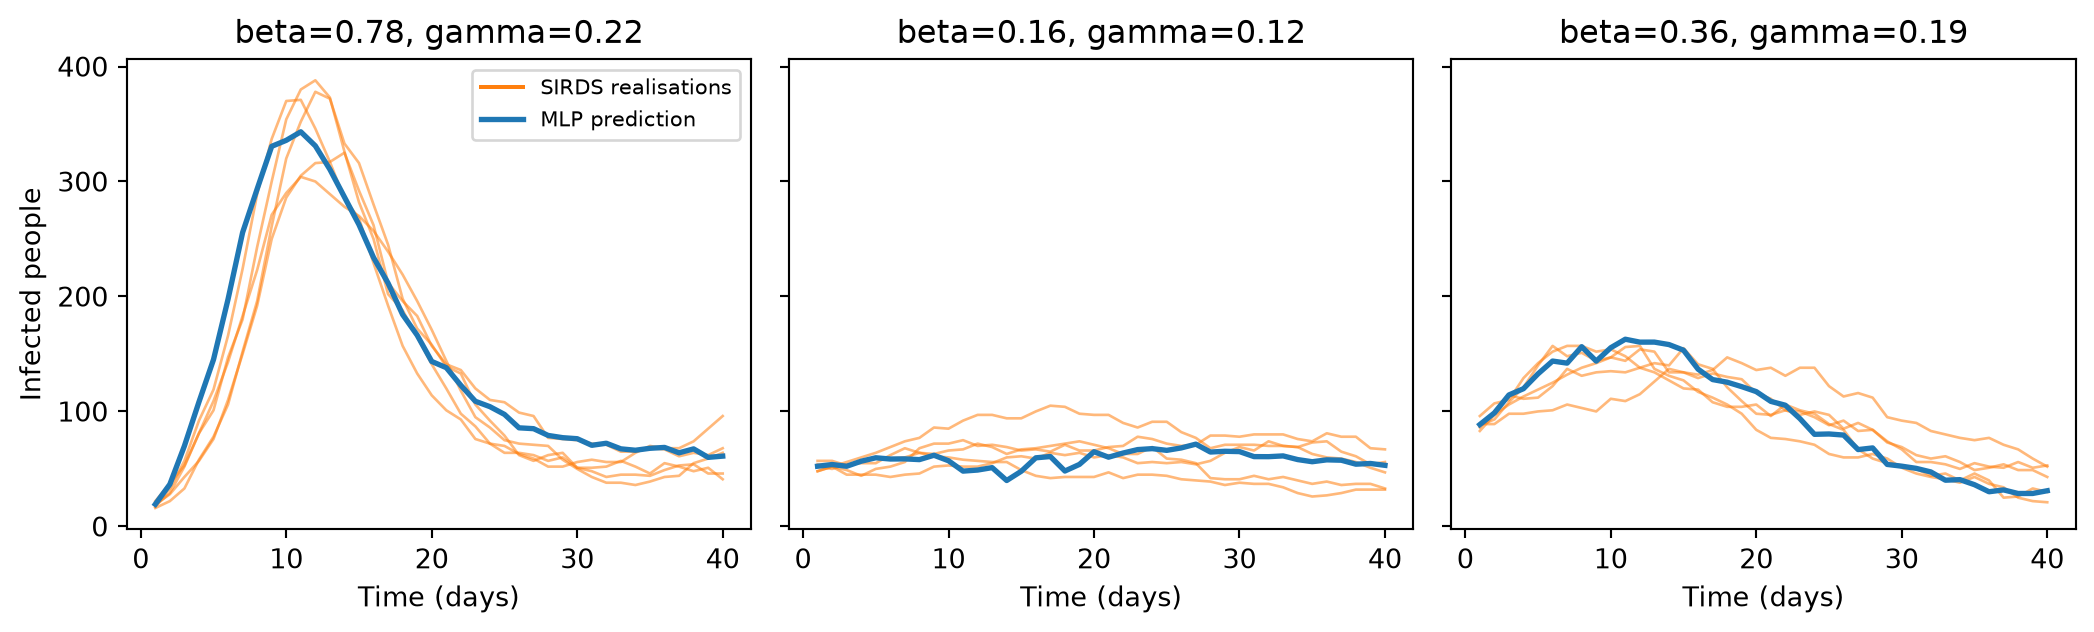

In [3]:
#| fig-cap: "MLP fitted on the 60 training settings in the bundled SIRDS bank, compared with five realisations at each of three test settings."
plot_predictions(mlp, "MLP prediction")

*MLP fitted on the 60 training settings in the bundled SIRDS bank, compared with five realisations at each of three test settings.*

The MLP is deterministic: repeated calls at the same inputs give the same
trajectory. It aims to reproduce the average response, rather than the
variation between realisations.

Some held-out settings fall just beyond the ranges covered by the training
partition. METIS warns when a prediction extrapolates; this is useful when
checking where the simulation bank may need extending.

## Training a transformer

Next we'll try a transformer. All we need to change is the model choice.
The default architecture has two layers with width 64:

In [4]:
transformer = Surrogate("transformer").fit(
    split.train, split.validation, config=config
)

As before, we can view its predictions:

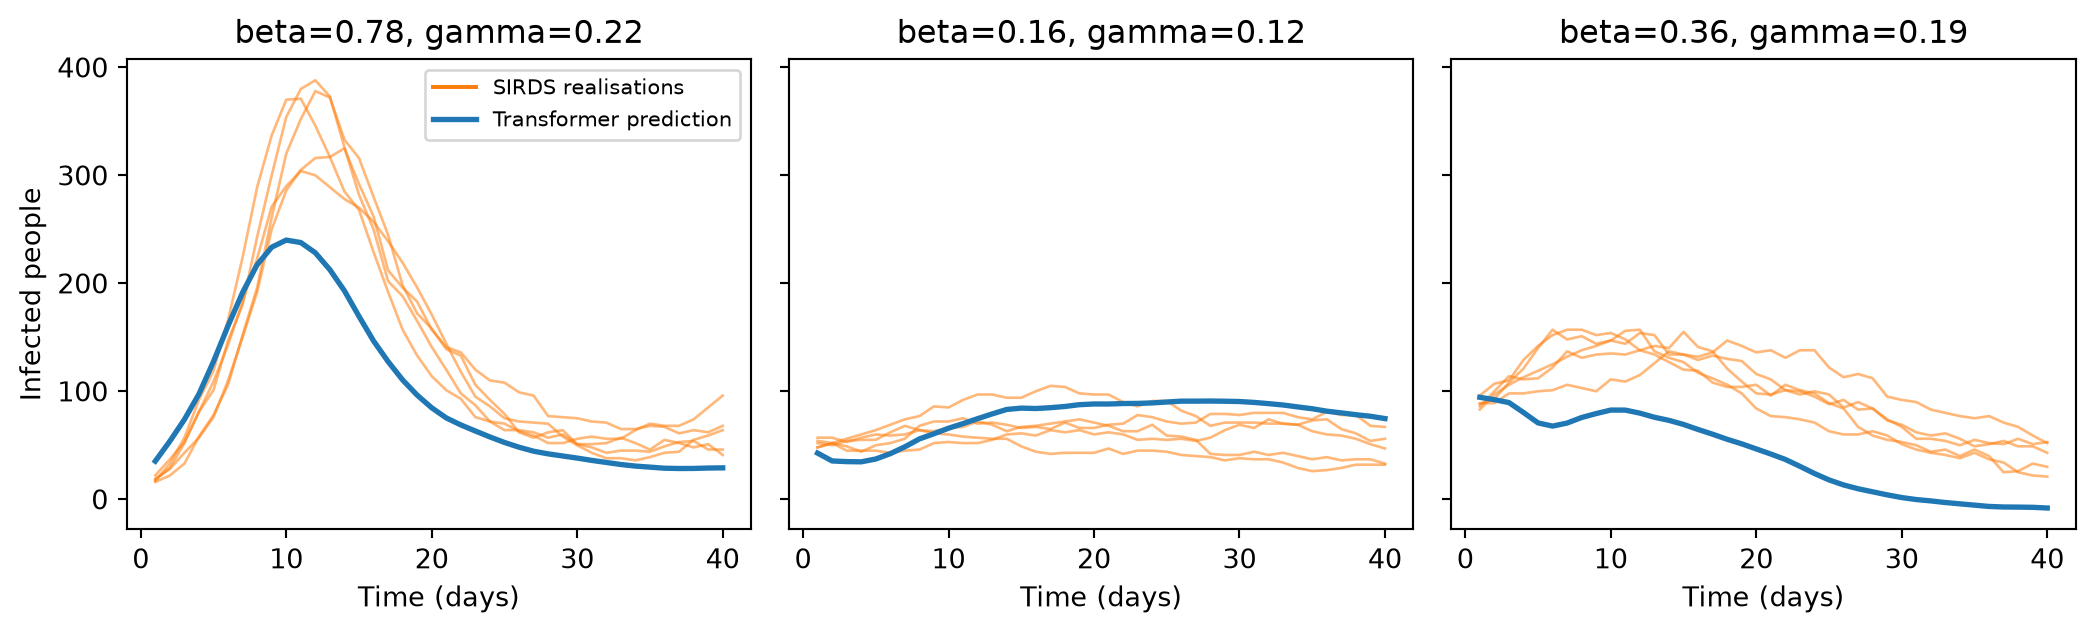

In [5]:
#| fig-cap: "Autoregressive transformer fitted on the same 60 SIRDS training settings and evaluated at the same three test settings as the MLP."
plot_predictions(transformer, "Transformer prediction")

*Autoregressive transformer fitted on the same 60 SIRDS training settings and evaluated at the same three test settings as the MLP.*

The transformer generates the trajectory one step at a time. It is also
deterministic. Errors can accumulate as it feeds its predictions into later
steps, so always check complete trajectories rather than just the training
loss. The [transformer page](https://ojwatson.github.io/metis/models/transformer.html) explains the architecture.

## Training a flow matching model

Again, we change the model choice and keep the data split. Flow matching is
stochastic: we can generate several different trajectories for the same inputs.

In [6]:
flow = Surrogate("flow_matching").fit(
    split.train, split.validation, config=config
)

Solid blue is the mean of 30 generated trajectories; light blue shows the
individual draws. Orange still shows the five SIRDS realisations. These draws
represent variability under the fitted surrogate, not uncertainty about its
accuracy.

/home/runner/work/metis/metis/src/metis/surrogate.py:737: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


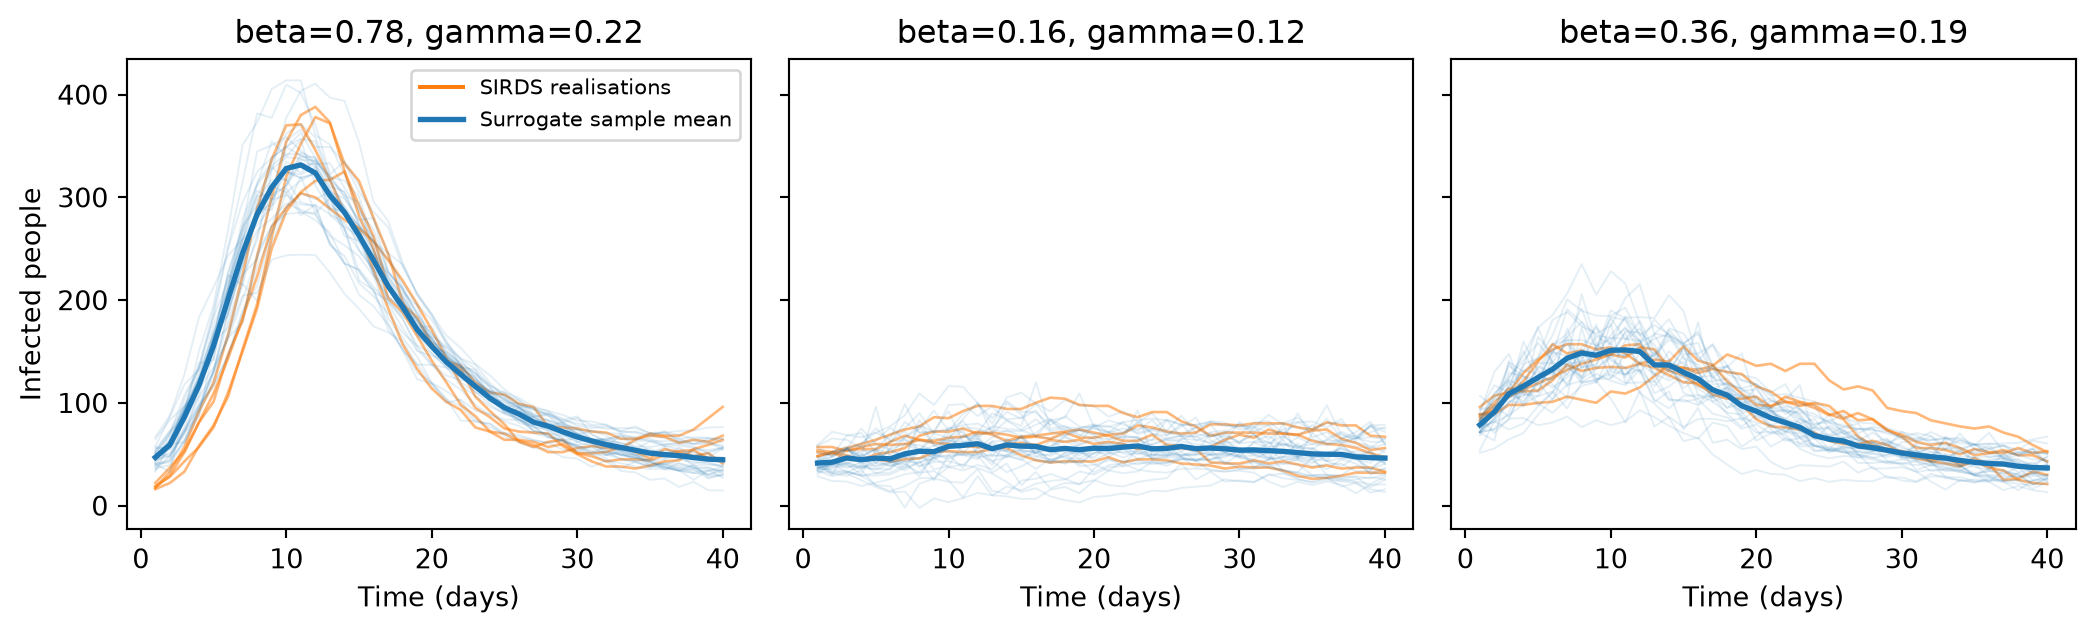

In [7]:
#| fig-cap: "Flow matching fitted on the same 60 SIRDS training settings. Thirty surrogate draws are compared with five SIRDS realisations at each test setting."
plot_predictions(flow, "Surrogate sample mean")

*Flow matching fitted on the same 60 SIRDS training settings. Thirty surrogate draws are compared with five SIRDS realisations at each test setting.*

More training and a larger model may improve this fit. More solver steps at
sampling time can reduce integration error, but do not replace training; see
[flow matching](https://ojwatson.github.io/metis/models/flow-matching.html) for these settings.

## Checking the fit

Plots are useful, but we also need measurements across the whole test set.
`evaluate` compares predictions with the simulations and reports errors in
the original units. For flow matching it also evaluates the distribution of
generated trajectories.

In [8]:
reports = {
    "MLP": evaluate(mlp, split.test),
    "Transformer": evaluate(transformer, split.test),
    "Flow matching": evaluate(flow, split.test, n_samples=30, num_steps=30),
}
comparison = pd.DataFrame([
    {"Model": name, "Test RMSE (people)": report.metrics["rmse"],
     "Replicate-mean RMSE (people)": report.metrics["replicate_mean_rmse"]}
    for name, report in reports.items()
])
comparison.round(2)

/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0', 'gamma', 'omega', 'mu']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)
/home/runner/work/metis/metis/src/metis/surrogate.py:737: UserWarning: Inputs outside the training ranges for ['I_0', 'gamma', 'omega', 'mu']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


,Model,Test RMSE (people),Replicate-mean RMSE (people)
0,MLP,36.51,30.24
1,Transformer,95.92,93.71
2,Flow matching,33.96,26.84


These are three short tutorial fits, all trained on the same 60 settings and
checked on the same 20 test settings. They are not a tuned comparison of model
families. The table pools errors across all four compartments and all time
points. RMSE against individual runs includes stochastic differences; the
replicate-mean error compares the prediction with the average of the five
realisations at each setting. Neither quantity establishes that a surrogate is
good enough for your intended use.

Inspect individual outputs as well. For flow matching, the coverage column is
the fraction of observed counts inside the model's pointwise 90% predictive
interval; it should be near 0.9 across a sufficiently large evaluation bank if
those intervals are well calibrated. Wide intervals alone are not a good fit,
so compare interval width and CRPS too (smaller CRPS is better).

In [9]:
reports["Flow matching"].by_output

output,rmse,mae,predictive_coverage_90,predictive_interval_width_90,crps
str,f64,f64,f64,f64,f64
"""S_t""",48.121087,34.902845,0.8285,117.138417,25.209454
"""I_t""",31.437172,23.007315,0.76,68.062174,17.365459
"""R_t""",33.630211,23.458688,0.8595,89.932018,17.292977
"""D_t""",13.306901,9.166052,0.82875,31.554966,6.599759


If predictions are poor, first check the training history. In the MLP, training
and validation losses both measure squared error after scaling. A rising
validation loss while training loss falls is a sign of overfitting; if both
remain high, try more training, a different learning rate or a larger model.

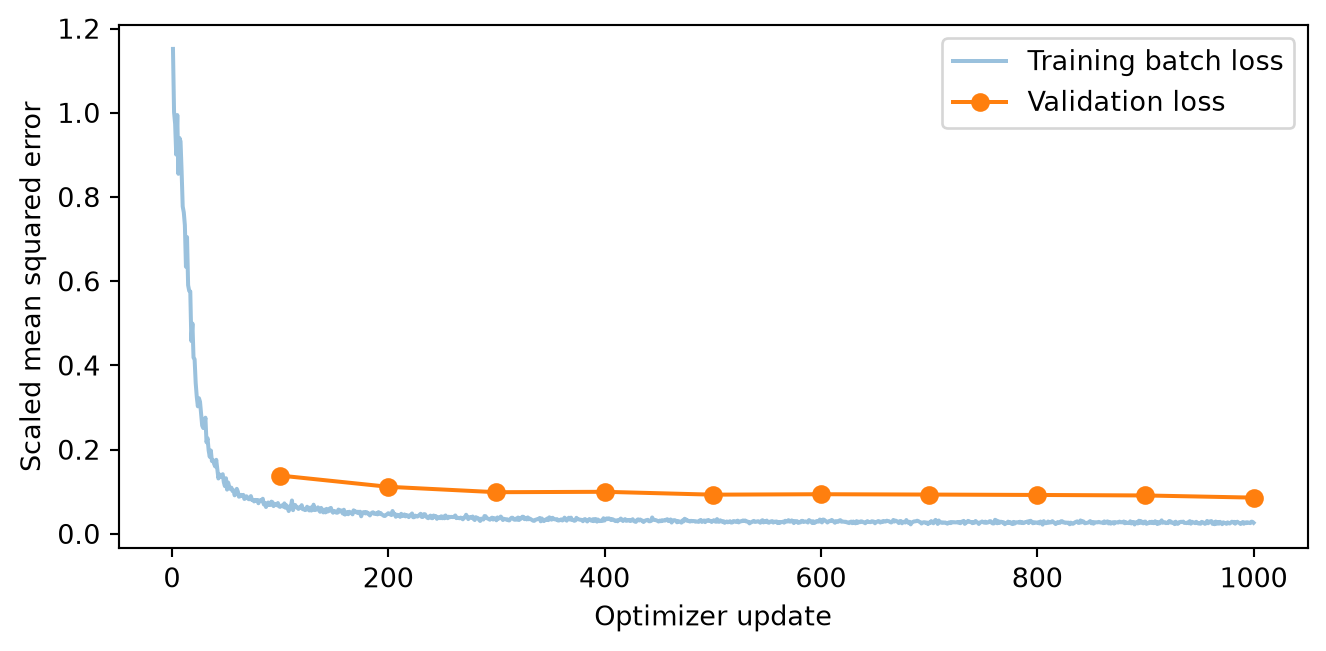

In [10]:
#| fig-cap: "MLP learning curve for the bundled SIRDS training and validation partitions. Test data are not used to select weights."
history = pd.DataFrame(mlp.history)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(history.step, history.train_loss, alpha=0.45, label="Training batch loss")
validation = history.dropna(subset=["validation_loss"])
ax.plot(validation.step, validation.validation_loss, "o-", label="Validation loss")
ax.set(xlabel="Optimizer update", ylabel="Scaled mean squared error")
ax.legend()
fig.tight_layout()
plt.show()

*MLP learning curve for the bundled SIRDS training and validation partitions. Test data are not used to select weights.*

Use `reports["MLP"].worst_groups(3)` to find parameter settings with large
errors. If these lie in sparsely sampled regions, more simulations there may
help. The [`suggest_simulations` function](https://ojwatson.github.io/metis/package/api.html#other-modules)
can select new settings from a table of candidate inputs to improve coverage; it uses distances in
parameter space, not an estimate of model error.

Also check the properties your simulator must preserve. For SIRDS, counts
should be nonnegative, deaths should not decrease, and the four compartments
should sum to 1,000. The neural architectures do not enforce these properties.
The [evaluation reference](https://ojwatson.github.io/metis/package/api.html#evaluationreport) describes explicit
constraint checks. Use validation data for tuning; if test errors influence
changes to the surrogate or bank, reserve fresh simulations for a final check.

Try changing `steps`, `learning_rate` or `batch_size` in `TrainingConfig`, or the
architecture options in `Surrogate`. Compare validation predictions using the
same split. Training losses from different model families have different
meanings and should not be ranked against each other.

You can run the same package workflow using Hydra, for example:

```bash
uv run metis train model=mlp training.steps=1000 plot.enabled=true
```

See the [Hydra walkthrough](https://ojwatson.github.io/metis/basics/hydra.html) for configuration files and overrides.
For longer runs you can also [track training with W&B](https://ojwatson.github.io/metis/sweeping/wandb.html).

Finally, save the fitted MLP for the next part:

In [11]:
mlp.save("sirds_surrogate.pt")
print("Saved sirds_surrogate.pt")

Saved sirds_surrogate.pt


Next, [load the surrogate and use it for new predictions](https://ojwatson.github.io/metis/basics/saving-and-loading.html).